# PASE ORACLE ES_01 OF LAB_02

## Qiskit implementation ob phase oracles

In [12]:
%pip install matplotlib pylatexenc
from qiskit import QuantumCircuit
from qiskit import QuantumRegister
from qiskit import transpile
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.visualization import plot_histogram

Note: you may need to restart the kernel to use updated packages.


In [ ]:
def adder_2bit() -> QuantumCircuit:

    # Input registers:  (we are creating registers that contain 1 qubit each)
    A0 = QuantumRegister(1, "A0")
    B0 = QuantumRegister(1, "B0")
    A1 = QuantumRegister(1, "A1")
    B1 = QuantumRegister(1, "B1")

    # Output registers:
    S0 = QuantumRegister(1, "S0")
    S1 = QuantumRegister(1, "S1")
    C2 = QuantumRegister(1, "C2")

    adder = QuantumCircuit(
        A0, B0, A1, B1, S0, S1, C2,
        name = "adder_2bit"
    )

    # Compute temporary C1:
    adder.ccx(A0[0], B0[0], S0[0])
    # Compute P = A1 XOR B1:
    adder.cx([A1[0], B1[0]], S1[0])
    # Compute final carry C2:
    adder.ccx(A1[0], B1[0], C2[0])
    adder.ccx(S1[0], S0[0], C2[0])
    # Compute S1:
    adder.cx(S0[0], S1[0])
    # Uncompute C1:
    adder.ccx(A0[0], B0[0], S0[0])
    # Compute S0:
    adder.cx([A0[0], B0[0]], S0[0])

    return adder


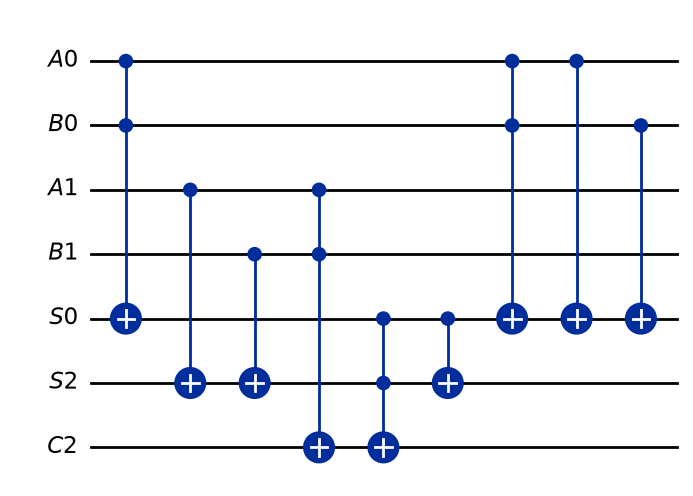

In [9]:
qc = adder_2bit()
display(qc.draw("mpl", justify="left", fold=-1))

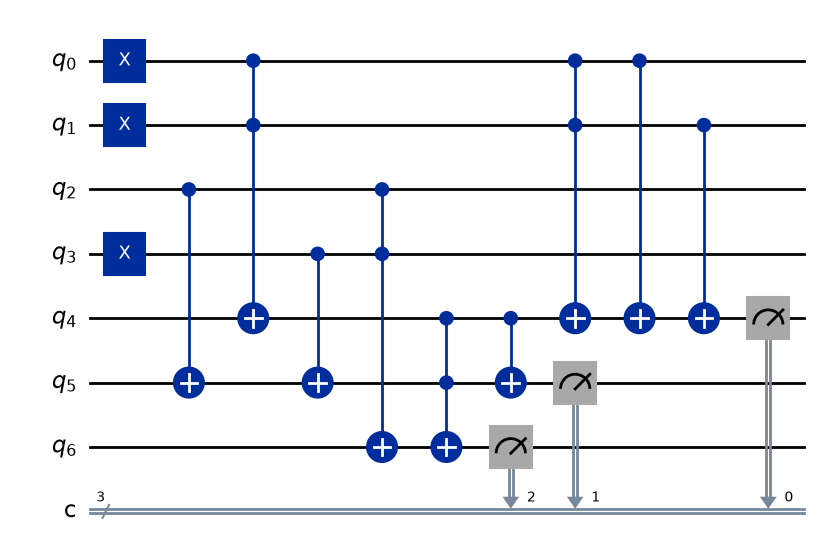

{'100': 1024}


In [ ]:
qc = QuantumCircuit(7, 3)

# Initialize inputs A = 01, B = 11
qc.x([0, 1, 3])

# Apply your adder
qc.compose(adder_2bit(), inplace=True)

# Measure S0, S1, C2
qc.measure([4, 5, 6], [0, 1, 2])

display(qc.draw("mpl", fold=-1))

simulator = BasicSimulator()

result = simulator.run(
    transpile(qc, simulator),
    shots=1024
).result()

print(result.get_counts())